# O filme é um blockbuster?
### Árvores de decisão para prever o sucesso de bilheteria antes da estreia

**Universidade Federal de Pernambuco · Centro de Informática (CIn)**  
Probabilidade e Estatística · 2026.2 · Projeto 2 · **Grupo 6**

| Integrante | Login |
|---|---|
| Arthur Sean Cerqueira Campos | ascc2 |
| Isabela Possídio Amorim | ipa |
| João Guilherme Lemos Duarte | jgldo |
| Luis Miguel | lmfs3 |
| Mirella Fontinelle | mlfm |
| Severino João da Cruz Júnior | sjcj2 |

---

**Sumário**

1. Introdução: contextualização, objetivo e descrição dos dados
2. Análise Exploratória de Dados (EDA): limpeza, análise univariada, análise bivariada e multivariada, insights
3. Validação Estatística (Teste de Hipóteses)
4. Pré-processamento e Aplicação da Técnica
5. Resultados e Interpretação
6. Conclusão

Referências ao final do notebook.

## Configuração do ambiente

A célula abaixo carrega os pacotes usados ao longo do notebook (instalando os que faltarem) e define o padrão visual dos gráficos e algumas funções auxiliares reaproveitadas nas seções seguintes.

In [1]:
# Pacotes da EDA. Os de modelagem (rpart, rpart.plot, caret, pROC) são carregados na seção 4.
pacotes <- c("ggplot2", "dplyr", "tidyr", "scales")
faltando <- pacotes[!pacotes %in% rownames(installed.packages())]
if (length(faltando) > 0) install.packages(faltando, quiet = TRUE)
invisible(lapply(pacotes, function(p) suppressPackageStartupMessages(library(p, character.only = TRUE))))

set.seed(2026)   # semente única do projeto: garante que splits e validações sejam reproduzíveis
options(repr.plot.width = 10, repr.plot.height = 4.5, scipen = 999, width = 120)

# ---- Padrão visual dos gráficos ----
AZUL  <- "#2F5F9E"   # cor principal (barras e histogramas)
CINZA <- "#B5BFCC"   # categoria de contraste (ex.: não blockbuster)
TINTA <- "#1B2B48"   # linhas de referência e textos

theme_set(
  theme_minimal(base_size = 13) +
    theme(panel.grid.minor   = element_blank(),
          panel.grid.major.x = element_blank(),
          plot.title         = element_text(face = "bold", color = TINTA),
          plot.subtitle      = element_text(color = "grey35"),
          axis.title         = element_text(color = "grey30"))
)

# ---- Funções auxiliares ----
# Medidas-resumo de uma variável numérica
resumo_num <- function(x) {
  q   <- quantile(x, c(.25, .5, .75))
  iqr <- q[[3]] - q[[1]]
  data.frame(
    n          = length(x),
    media      = mean(x),
    mediana    = q[[2]],
    desvio     = sd(x),
    minimo     = min(x),
    Q1         = q[[1]],
    Q3         = q[[3]],
    maximo     = max(x),
    CV_pct     = 100 * sd(x) / mean(x),
    assimetria = mean((x - mean(x))^3) / sd(x)^3,
    outliers   = sum(x < q[[1]] - 1.5 * iqr | x > q[[3]] + 1.5 * iqr)
  )
}

# Valores em milhões de dólares (US$ 15,0 mi)
mi  <- label_number(scale = 1e-6, prefix = "US$ ", suffix = " mi",
                    big.mark = ".", decimal.mark = ",", accuracy = 0.1)
mi0 <- label_number(scale = 1e-6, prefix = "US$ ", suffix = " mi",
                    big.mark = ".", decimal.mark = ",", accuracy = 1)

# Números no padrão brasileiro: 4.327 e 86,54%
br <- function(x, d = 0) formatC(x, format = "f", digits = d, big.mark = ".", decimal.mark = ",")

# 1. Introdução

## 1.1 Contextualização

A indústria cinematográfica envolve investimentos altos e retorno incerto: um mesmo orçamento e um mesmo estilo de filme podem resultar em um fracasso financeiro ou em um sucesso gigante de bilheteria. Para um estúdio, a decisão de quanto investir em um projeto é tomada **antes da estreia**, com informação incompleta. Identificar antecipadamente quais características estão associadas ao sucesso ajuda a decidir onde vale a pena arriscar.

No Projeto 1, propusemos atacar esse problema com **árvores de decisão**, inspirados no estudo de Afonso et al. (2012), que usou uma árvore CART enxuta (apenas duas variáveis) para classificar o risco de influenza em pacientes, com AUROC de 0,76 na validação. As árvores foram escolhidas porque:

- geram regras do tipo *se… então…* fáceis de explicar para quem toma a decisão de negócio;
- aceitam variáveis numéricas e categóricas sem normalização;
- capturam interações entre as variáveis.

Para isso, usamos o dataset **"What Makes a Movie a Blockbuster? – 5,000 Films with Ratings, Budgets & Revenue"**, que simula o cenário de um estúdio que precisa decidir quanto investir antes de saber se o filme vai render.

## 1.2 Objetivo

**Pergunta:** usando apenas atributos **conhecidos antes do lançamento** (década, gênero, duração e orçamento), uma árvore de decisão consegue distinguir os filmes *blockbusters* dos demais?

**Objetivo:** construir e interpretar uma árvore de decisão de classificação para a variável-alvo `blockbuster` e avaliá-la em dados que ela não viu durante o treino. No dataset, um filme é **blockbuster** (`blockbuster = 1`) quando:

> **receita > 3 × orçamento** &nbsp;e&nbsp; **receita > US\$ 100 milhões**

**Hipóteses definidas no Projeto 1:**

- **H0:** a árvore **não supera** o *baseline* que sempre prevê a classe majoritária.
- **H1:** a árvore **supera** o *baseline* em F1 da classe blockbuster no conjunto de teste.

**Critério de sucesso:** F1 acima do *baseline* e uma árvore legível, com profundidade menor que 4. A expectativa inicial era que **orçamento e gênero** aparecessem nas primeiras divisões.

**Variáveis que ficam de fora do modelo principal:**

- `revenue_usd`, `profit_usd` e `roi` derivam diretamente da receita, que define o alvo. Usá-las seria **vazamento de informação** (*data leakage*): o modelo "veria a resposta".
- `rating`, `vote_count` e `popularity` só são conhecidas **depois do lançamento**, quando a decisão de investimento já foi tomada.

Essas variáveis aparecem apenas nos **experimentos de controle** (seção 4), para mostrar o efeito do vazamento e o ganho que os sinais do público trariam.

## 1.3 Descrição dos dados

- **Fonte:** Kaggle, *"What Makes a Movie a Blockbuster? – 5,000 Films with Ratings, Budgets & Revenue"*, de V. R. Leelavathi, licença CC0 (domínio público).
- **Tamanho:** 5.000 filmes lançados entre 1980 e 2024, com 14 colunas.
- **Natureza:** o dataset é **sintético**, ou seja, gerado por simulação (os títulos vão de `Movie_0001` a `Movie_5000`). Por isso, as conclusões valem para o **método**, não para a indústria real.

**Dicionário de dados**

| Variável | Tipo | Descrição | Papel na análise |
|---|---|---|---|
| `movie_id` | inteiro | Identificador único do filme | Identificador |
| `title` | texto | Título sintético (`Movie_0001` a `Movie_5000`) | Identificador |
| `year` | inteiro | Ano de lançamento (1980 a 2024) | Informativa (redundante com `decade`) |
| `decade` | categórica | Década de lançamento (1980s a 2020s) | **Preditora** |
| `genre` | categórica | Gênero principal (10 categorias) | **Preditora** |
| `runtime_min` | inteiro | Duração em minutos (60 a 185) | **Preditora** |
| `budget_usd` | numérica | Orçamento de produção, em US\$ | **Preditora** |
| `revenue_usd` | numérica | Receita de bilheteria, em US\$ | Excluída (vazamento) |
| `profit_usd` | numérica | Lucro = receita − orçamento | Excluída (vazamento) |
| `roi` | numérica | Retorno = lucro / orçamento | Excluída (vazamento) |
| `rating` | numérica | Nota média do público (1,0 a 10,0) | Excluída (pós-lançamento) |
| `vote_count` | inteiro | Número de votos | Excluída (pós-lançamento) |
| `popularity` | numérica | Índice de popularidade | Excluída (pós-lançamento) |
| `blockbuster` | binária | 1 = blockbuster; 0 = não blockbuster | **Alvo** |

Gêneros: Action, Adventure, Animation, Comedy, Documentary, Drama, Horror, Romance, Sci-Fi e Thriller.

`year` e `decade` carregam a mesma informação. Seguindo o plano do Projeto 1, o modelo usa a **década**; o ano é usado apenas na análise exploratória.

# 2. Análise Exploratória de Dados (EDA)

## 2.1 Carregamento e Limpeza dos Dados

### Carregamento

O arquivo `movie_blockbusters.csv` é lido da pasta do notebook. Se ele não estiver lá (por exemplo, no Google Colab), é lido diretamente do repositório do grupo no GitHub.

In [2]:
arquivo <- "movie_blockbusters.csv"
url     <- "https://raw.githubusercontent.com/arthursean/decision-tree-blockbuster/main/movie_blockbusters.csv"

df <- read.csv(if (file.exists(arquivo)) arquivo else url, stringsAsFactors = FALSE)

dim(df)
head(df)

[1] 5000   14

,movie_id,title,year,decade,genre,runtime_min,budget_usd,revenue_usd,profit_usd,roi,rating,vote_count,popularity,blockbuster
,<int>,<chr>,<int>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<int>
1,1,Movie_0001,2020,2020s,Comedy,96,20892329,27392091.7,6499763.1,0.311,7.0,216326,9.64,0
2,2,Movie_0002,1981,1980s,Sci-Fi,128,306333628,1237478549.0,931144920.9,3.040,5.3,49703,7.65,1
3,3,Movie_0003,1995,1990s,Horror,79,8793950,4667245.8,-4126704.3,-0.469,3.4,9476,16.68,0
4,4,Movie_0004,1988,1980s,Comedy,101,3871710,1612737.4,-2258972.1,-0.583,8.2,15698,2.93,0
5,5,Movie_0005,2023,2020s,Documentary,75,1283539,574346.9,-709191.7,-0.553,4.3,38698,9.10,0
6,6,Movie_0006,1985,1980s,Adventure,137,17573805,213596355.1,196022550.4,11.154,6.0,4507,3.59,1


A base tem **5.000 linhas** (um filme por linha) e **14 colunas**, como descrito no dicionário de dados.

### Estrutura e tipos das variáveis

In [3]:
str(df)

'data.frame':	5000 obs. of  14 variables:
 $ movie_id   : int  1 2 3 4 5 6 7 8 9 10 ...
 $ title      : chr  "Movie_0001" "Movie_0002" "Movie_0003" "Movie_0004" ...
 $ year       : int  2020 1981 1995 1988 2023 1985 2007 1981 1993 2012 ...
 $ decade     : chr  "2020s" "1980s" "1990s" "1980s" ...
 $ genre      : chr  "Comedy" "Sci-Fi" "Horror" "Comedy" ...
 $ runtime_min: int  96 128 79 101 75 137 141 93 84 129 ...
 $ budget_usd : num  20892329 306333628 8793950 3871710 1283539 ...
 $ revenue_usd: num  27392092 1237478549 4667246 1612737 574347 ...
 $ profit_usd : num  6499763 931144921 -4126704 -2258972 -709192 ...
 $ roi        : num  0.311 3.04 -0.469 -0.583 -0.553 ...
 $ rating     : num  7 5.3 3.4 8.2 4.3 6 4 3.8 6.5 4.7 ...
 $ vote_count : int  216326 49703 9476 15698 38698 4507 29592 7481 12361 13851 ...
 $ popularity : num  9.64 7.65 16.68 2.93 9.1 ...
 $ blockbuster: int  0 1 0 0 0 1 0 0 0 1 ...


O `str()` mostra **3 colunas de texto** (`title`, `decade` e `genre`), **5 colunas inteiras** (`movie_id`, `year`, `runtime_min`, `vote_count` e `blockbuster`) e **6 numéricas contínuas** (`budget_usd`, `revenue_usd`, `profit_usd`, `roi`, `rating` e `popularity`). Todos os tipos foram lidos corretamente. Só `decade` e `genre` precisarão ser convertidas para fator (variável categórica), o que é feito no fim desta seção.

### Resumo estatístico

In [4]:
summary(df)

    movie_id       title                year         decade             genre            runtime_min   
 Min.   :   1   Length:5000        Min.   :1980   Length:5000        Length:5000        Min.   : 60.0  
 1st Qu.:1251   Class :character   1st Qu.:1991   Class :character   Class :character   1st Qu.: 93.0  
 Median :2500   Mode  :character   Median :2002   Mode  :character   Mode  :character   Median :109.0  
 Mean   :2500                      Mean   :2002                                         Mean   :109.4  
 3rd Qu.:3750                      3rd Qu.:2013                                         3rd Qu.:126.0  
 Max.   :5000                      Max.   :2024                                         Max.   :185.0  
   budget_usd          revenue_usd            profit_usd               roi              rating         vote_count      
 Min.   :    105490   Min.   :      14032   Min.   : -800900200   Min.   :-0.9800   Min.   : 1.000   Min.   :      87  
 1st Qu.:   5072756   1st Qu.:  

O `summary()` já antecipa as principais características da base:

- **Orçamento, receita, votos e popularidade** têm a média muito acima da mediana (por exemplo, orçamento com mediana de US\$ 15,0 mi e média de US\$ 43,2 mi), o que indica **forte assimetria à direita**. Os máximos também são extremos (orçamento de US\$ 2,37 bi e receita de US\$ 14,96 bi). Essas distribuições são analisadas na seção 2.2.
- **Duração** (60 a 185 min, média de 109,4) e **nota** (1 a 10, média de 6,0) têm média e mediana praticamente iguais, sinal de distribuições simétricas.
- O **ROI** vai de −0,98 (o filme perdeu 98% do orçamento) a 43,3 (rendeu 43 vezes o orçamento).
- A média de `blockbuster` é **0,1346**: só 13,46% dos filmes são blockbusters (seção 2.2.1).

### Valores faltantes

In [5]:
colSums(is.na(df))

# Strings vazias nas colunas de texto
sapply(df[sapply(df, is.character)], function(x) sum(trimws(x) == ""))

movie_id       title        year      decade       genre runtime_min  budget_usd revenue_usd  profit_usd         roi 
          0           0           0           0           0           0           0           0           0           0 
     rating  vote_count  popularity blockbuster 
          0           0           0           0

title decade  genre 
     0      0      0

**Nenhuma coluna tem valores faltantes** (`NA`) nem textos vazios. Não foi preciso remover linhas nem imputar valores.

### Duplicados

In [6]:
c(linhas_duplicadas   = sum(duplicated(df)),
  movie_id_repetidos  = sum(duplicated(df$movie_id)),
  titulos_repetidos   = sum(duplicated(df$title)))

linhas_duplicadas movie_id_repetidos  titulos_repetidos 
                 0                  0                  0

**Não há duplicados**: nenhuma linha inteira repetida, nenhum `movie_id` repetido e nenhum título repetido.

### Consistência dos dados

Além de faltantes e duplicados, verificamos se os valores fazem sentido (estão dentro dos limites esperados) e se as colunas calculadas a partir de outras batem entre si. Cada regra abaixo conta quantos filmes a **violam**.

In [7]:
checagens <- data.frame(
  regra = c(
    "Ano fora de 1980 a 2024",
    "Nota fora de 0 a 10",
    "Orçamento <= 0",
    "Receita <= 0",
    "Duração <= 0",
    "Votos ou popularidade negativos",
    "Década não corresponde ao ano",
    "Lucro diferente de receita - orçamento",
    "ROI diferente de lucro / orçamento",
    "Alvo diferente da definição (receita > 3x orçamento e > US$ 100 mi)"
  ),
  violacoes = c(
    sum(df$year < 1980 | df$year > 2024),
    sum(df$rating < 0 | df$rating > 10),
    sum(df$budget_usd <= 0),
    sum(df$revenue_usd <= 0),
    sum(df$runtime_min <= 0),
    sum(df$vote_count < 0 | df$popularity < 0),
    sum(paste0(floor(df$year / 10) * 10, "s") != df$decade),
    sum(abs(df$revenue_usd - df$budget_usd - df$profit_usd) > 1),               # tolerância de US$ 1 (arredondamento)
    sum(abs(round(df$profit_usd / df$budget_usd, 3) - df$roi) > 0.002),         # ROI vem com 3 casas decimais
    sum(as.integer(df$revenue_usd > 3 * df$budget_usd & df$revenue_usd > 1e8) != df$blockbuster)
  )
)
checagens

regra,violacoes
<chr>,<int>
Ano fora de 1980 a 2024,0
Nota fora de 0 a 10,0
Orçamento <= 0,0
Receita <= 0,0
Duração <= 0,0
Votos ou popularidade negativos,0
Década não corresponde ao ano,0
Lucro diferente de receita - orçamento,0
ROI diferente de lucro / orçamento,0


**Todas as 10 regras têm zero violações.** Em especial:

- a coluna `decade` corresponde exatamente ao ano de lançamento;
- `profit_usd` e `roi` foram calculados corretamente a partir da receita e do orçamento;
- a coluna `blockbuster` segue **exatamente** a definição do dataset (receita > 3× o orçamento **e** receita > US\$ 100 mi), então podemos usá-la como alvo sem recalcular.

### Ajuste de tipos

Por fim, convertemos as variáveis categóricas para fator. A década é ordenada cronologicamente. O alvo continua numérico (0/1) durante a EDA, porque isso permite calcular taxas com uma simples média; ele é convertido para fator na preparação do modelo (seção 4.1).

In [8]:
df$decade <- factor(df$decade, levels = c("1980s", "1990s", "2000s", "2010s", "2020s"))
df$genre  <- factor(df$genre)

# Grupos de variáveis, usados nas próximas seções
vars_pre       <- c("decade", "genre", "runtime_min", "budget_usd")   # preditoras (pré-lançamento)
vars_vazamento <- c("revenue_usd", "profit_usd", "roi")              # derivadas do alvo
vars_pos       <- c("rating", "vote_count", "popularity")            # pós-lançamento
alvo           <- "blockbuster"

str(df[, c(vars_pre, alvo)])

'data.frame':	5000 obs. of  5 variables:
 $ decade     : Factor w/ 5 levels "1980s","1990s",..: 5 1 2 1 5 1 3 1 2 4 ...
 $ genre      : Factor w/ 10 levels "Action","Adventure",..: 4 9 7 4 5 2 1 4 7 2 ...
 $ runtime_min: int  96 128 79 101 75 137 141 93 84 129 ...
 $ budget_usd : num  20892329 306333628 8793950 3871710 1283539 ...
 $ blockbuster: int  0 1 0 0 0 1 0 0 0 1 ...


### Conclusão da limpeza

A base está **completa, sem duplicados e internamente consistente**, então **nenhuma linha foi removida** e as 5.000 observações seguem para a análise. Os pontos de atenção, tratados nas próximas seções, são:

- **dados sintéticos:** as conclusões valem para o método, não para o mercado real de cinema;
- **valores financeiros extremos** (orçamento e receita com cauda longa), analisados na seção 2.2;
- **desbalanceamento do alvo** (13,46% de blockbusters), que define as métricas de avaliação do modelo.

## 2.2 Análise Univariada

Nesta etapa olhamos **cada variável isoladamente**, para entender sua distribuição (formato, centro, dispersão e valores extremos) antes de cruzá-las com o alvo na seção 2.3.

Analisamos com mais detalhe as variáveis que entram no modelo principal, ou seja, as conhecidas **antes da estreia**:

| Variável | Tipo | O que olhamos |
|---|---|---|
| `blockbuster` | alvo binário | proporção das classes |
| `budget_usd` | numérica contínua | histograma, boxplot, medidas-resumo, outliers |
| `runtime_min` | numérica discreta | histograma, boxplot, medidas-resumo |
| `genre` | categórica (10 níveis) | frequências absolutas e relativas |
| `decade` / `year` | categórica / numérica | frequências por década e por ano |

No fim, fazemos uma passagem rápida pelas variáveis que **não** entram no modelo principal (receita, nota, votos e popularidade), porque elas aparecem nos experimentos de controle da seção 4.

### 2.2.1 Variável-alvo: `blockbuster`

Começamos pelo alvo, porque a proporção das classes define como o modelo será avaliado.

blockbuster,n,classe,pct
<int>,<int>,<fct>,<dbl>
0,4327,Não blockbuster,86.54
1,673,Blockbuster,13.46


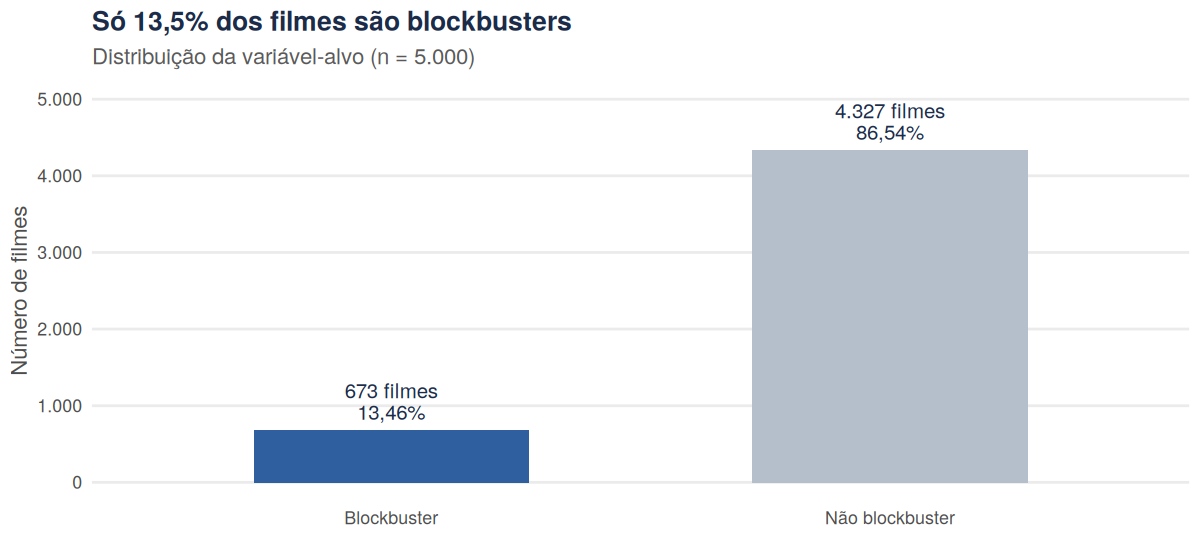

In [9]:
classes <- df %>%
  count(blockbuster) %>%
  mutate(classe = factor(ifelse(blockbuster == 1, "Blockbuster", "Não blockbuster"),
                         levels = c("Blockbuster", "Não blockbuster")),
         pct    = 100 * n / sum(n))
classes

ggplot(classes, aes(x = classe, y = n, fill = classe)) +
  geom_col(width = 0.55) +
  geom_text(aes(label = paste0(br(n), " filmes\n", br(pct, 2), "%")),
            vjust = -0.3, color = TINTA, size = 4.2, lineheight = 0.9) +
  scale_fill_manual(values = c("Blockbuster" = AZUL, "Não blockbuster" = CINZA), guide = "none") +
  scale_y_continuous(limits = c(0, 5000), labels = label_number(big.mark = ".", decimal.mark = ",")) +
  labs(title = "Só 13,5% dos filmes são blockbusters",
       subtitle = "Distribuição da variável-alvo (n = 5.000)",
       x = NULL, y = "Número de filmes")

**Observações**

- São **673 blockbusters (13,46%)** contra **4.327 não blockbusters (86,54%)**, uma razão de cerca de **1 para 6,4**. A base é **desbalanceada**.
- Consequência direta: um "modelo" que sempre responde *não blockbuster* acerta **86,5%** dos filmes sem aprender nada, mas tem recall e F1 iguais a **zero** para a classe que nos interessa. Por isso, como planejado no Projeto 1, a **acurácia não será a métrica principal**: avaliaremos **precisão, recall e F1 da classe blockbuster** e a AUROC.
- O desbalanceamento também justifica o **split 70/30 estratificado** (seção 4), para que treino e teste mantenham a mesma proporção de blockbusters (aproximadamente 13,5%).
- Esses valores completam o painel de classes apresentado no Projeto 1, que ainda não trazia as proporções.

### 2.2.2 Orçamento: `budget_usd`

O orçamento é a principal variável numérica pré-lançamento e, pela expectativa do Projeto 1, uma das candidatas às primeiras divisões da árvore.

In [10]:
resumo_orc <- resumo_num(df$budget_usd)
resumo_orc %>%
  mutate(across(c(media, mediana, desvio, minimo, Q1, Q3, maximo), mi),
         across(c(CV_pct, assimetria), ~ round(.x, 2)))

cat("Filmes com orçamento > US$ 100 mi:", sum(df$budget_usd > 1e8),
    paste0("(", br(100 * mean(df$budget_usd > 1e8), 1), "%)\n"))
cat("Filmes com orçamento > US$ 400 mi:", sum(df$budget_usd > 4e8), "\n")
cat("Percentis 90, 95 e 99:", mi(quantile(df$budget_usd, c(.90, .95, .99))), "\n")

n,media,mediana,desvio,minimo,Q1,Q3,maximo,CV_pct,assimetria,outliers
<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>
5000,"US$ 43,2 mi","US$ 15,0 mi","US$ 99,0 mi","US$ 0,1 mi","US$ 5,1 mi","US$ 41,9 mi","US$ 2.369,8 mi",229.06,8.69,523


Filmes com orçamento > US$ 100 mi: 507 (10,1%)


Filmes com orçamento > US$ 400 mi: 56 


Percentis 90, 95 e 99: US$ 101,0 mi US$ 162,6 mi US$ 412,7 mi 


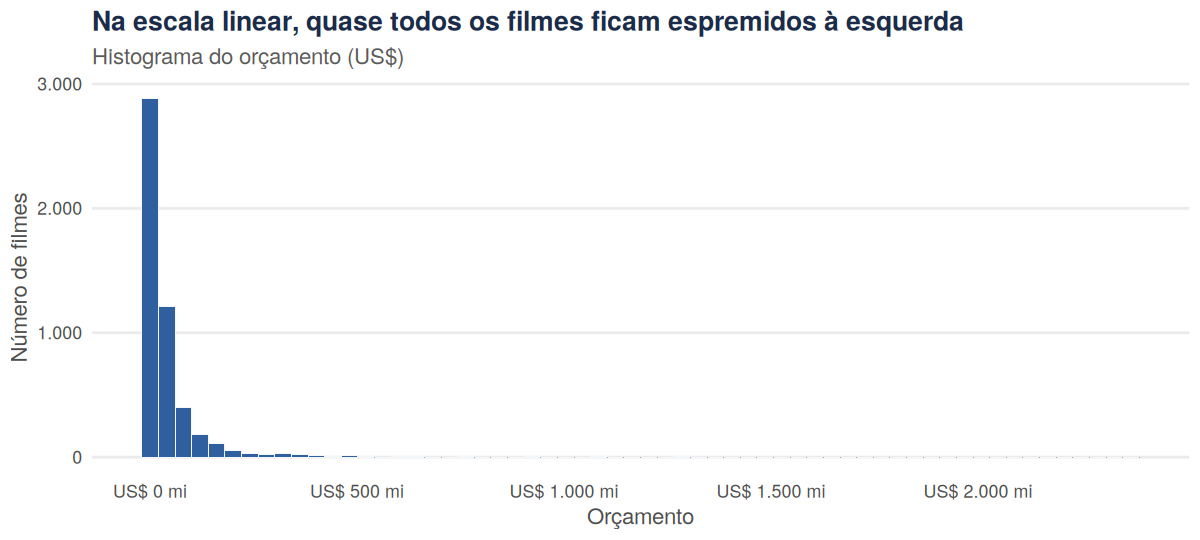

In [11]:
# Escala linear: mostra o problema da assimetria
ggplot(df, aes(x = budget_usd)) +
  geom_histogram(bins = 60, fill = AZUL, color = "white", linewidth = 0.2) +
  scale_x_continuous(labels = mi0, breaks = seq(0, 2e9, 5e8)) +
  scale_y_continuous(labels = label_number(big.mark = ".", decimal.mark = ",")) +
  labs(title = "Na escala linear, quase todos os filmes ficam espremidos à esquerda",
       subtitle = "Histograma do orçamento (US$)",
       x = "Orçamento", y = "Número de filmes")

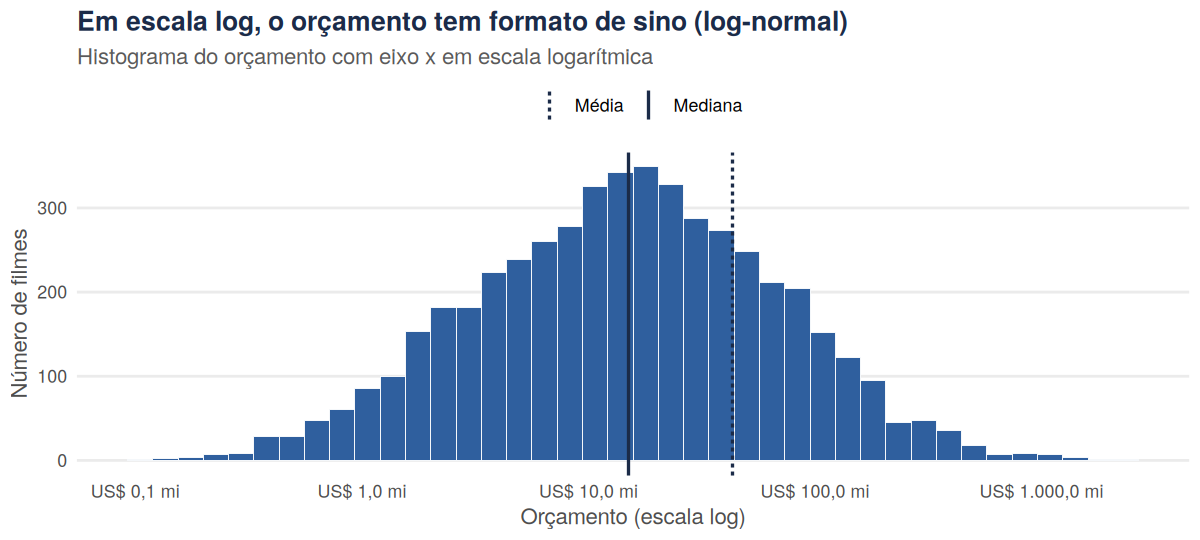

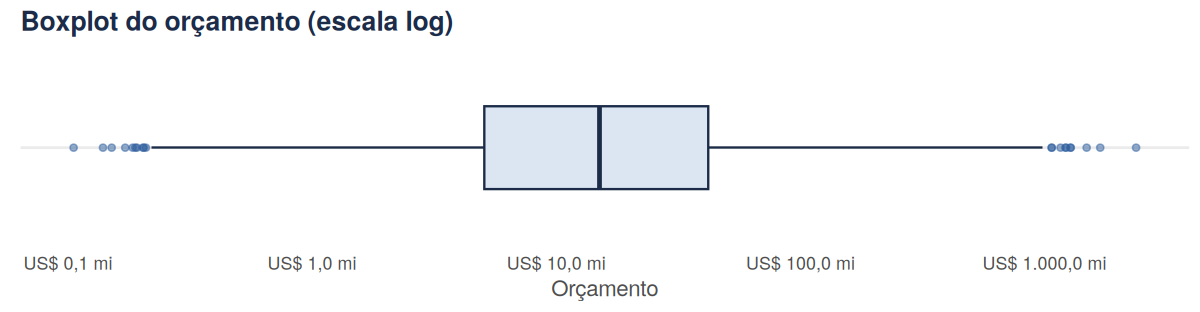

In [12]:
# Escala logarítmica: revela o formato real da distribuição
refs <- data.frame(tipo  = c("Mediana", "Média"),
                   valor = c(median(df$budget_usd), mean(df$budget_usd)))

ggplot(df, aes(x = budget_usd)) +
  geom_histogram(bins = 40, fill = AZUL, color = "white", linewidth = 0.2) +
  geom_vline(data = refs, aes(xintercept = valor, linetype = tipo), color = TINTA, linewidth = 0.7) +
  scale_linetype_manual(values = c("Mediana" = "solid", "Média" = "dashed"), name = NULL) +
  scale_x_log10(labels = mi, breaks = c(1e5, 1e6, 1e7, 1e8, 1e9)) +
  labs(title = "Em escala log, o orçamento tem formato de sino (log-normal)",
       subtitle = "Histograma do orçamento com eixo x em escala logarítmica",
       x = "Orçamento (escala log)", y = "Número de filmes") +
  theme(legend.position = "top")

options(repr.plot.height = 2.6)
ggplot(df, aes(x = budget_usd, y = "")) +
  geom_boxplot(fill = "#DCE5F2", color = TINTA, outlier.color = AZUL,
               outlier.alpha = 0.5, outlier.size = 1.4, width = 0.5) +
  scale_x_log10(labels = mi, breaks = c(1e5, 1e6, 1e7, 1e8, 1e9)) +
  labs(title = "Boxplot do orçamento (escala log)", x = "Orçamento", y = NULL)
options(repr.plot.height = 4.5)

**Observações**

- **Forte assimetria à direita.** A média (**US\$ 43,2 mi**) é quase **3 vezes** a mediana (**US\$ 15,0 mi**), e o coeficiente de assimetria é **8,7**. Metade dos filmes custa entre **US\$ 5,1 mi e US\$ 41,9 mi** (Q1 e Q3), mas a cauda vai até **US\$ 2,37 bi**.
- **Distribuição log-normal.** Em escala logarítmica o histograma vira um sino quase simétrico (assimetria do log ≈ **−0,06**), o que é coerente com a forma como o dataset sintético foi gerado.
- **Outliers.** Pelo critério de 1,5 × IIQ, **523 filmes (10,5%)** são outliers, todos no lado alto. Há **56 filmes acima de US\$ 400 mi** e o máximo (US\$ 2,37 bi) é bem maior que qualquer orçamento real de Hollywood, o que reforça que os dados são sintéticos.
- **Decisão: manter os outliers e não transformar a variável para o modelo.** A árvore escolhe pontos de corte ("orçamento > X?"), então só a **ordem** dos valores importa: aplicar log não muda as divisões possíveis, e os valores extremos não "puxam" o modelo como fariam numa regressão. O log é usado aqui **só para visualizar**.
- Cerca de **10% dos filmes** custam mais de US\$ 100 mi. Como a definição de blockbuster exige receita acima de US\$ 100 mi **e** de 3× o orçamento, espera-se que a relação entre orçamento e blockbuster seja forte, o que será verificado na seção 2.3.

### 2.2.3 Duração: `runtime_min`

In [13]:
resumo_num(df$runtime_min) %>% mutate(across(where(is.numeric), ~ round(.x, 2)))

table(cut(df$runtime_min, breaks = c(59, 90, 120, 150, 185),
          labels = c("60–90 min", "91–120 min", "121–150 min", "151–185 min")))

n,media,mediana,desvio,minimo,Q1,Q3,maximo,CV_pct,assimetria,outliers
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
5000,109.36,109,22.22,60,93,126,185,20.32,0.07,2



  60–90 min  91–120 min 121–150 min 151–185 min 
       1060        2327        1467         146 

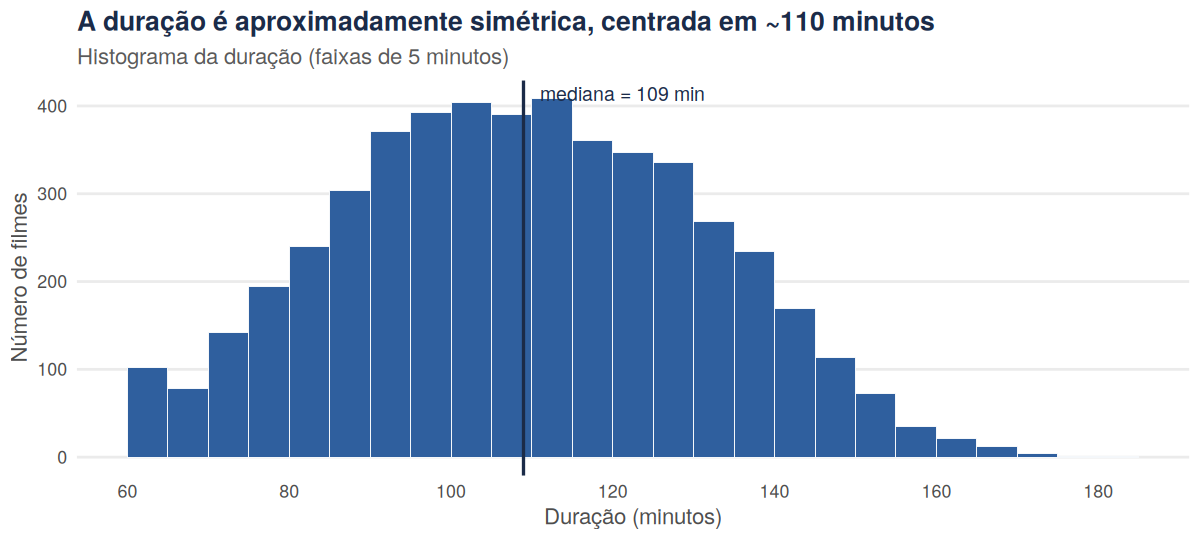

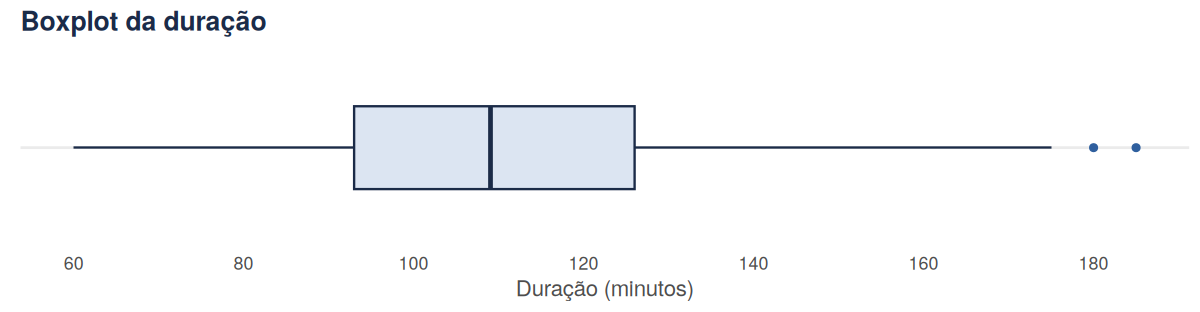

In [14]:
ggplot(df, aes(x = runtime_min)) +
  geom_histogram(binwidth = 5, boundary = 60, fill = AZUL, color = "white", linewidth = 0.2) +
  geom_vline(xintercept = median(df$runtime_min), color = TINTA, linewidth = 0.7) +
  annotate("text", x = median(df$runtime_min) + 2, y = Inf, vjust = 1.5, hjust = 0,
           label = paste0("mediana = ", median(df$runtime_min), " min"), color = TINTA, size = 4) +
  scale_x_continuous(breaks = seq(60, 190, 20)) +
  labs(title = "A duração é aproximadamente simétrica, centrada em ~110 minutos",
       subtitle = "Histograma da duração (faixas de 5 minutos)",
       x = "Duração (minutos)", y = "Número de filmes")

options(repr.plot.height = 2.6)
ggplot(df, aes(x = runtime_min, y = "")) +
  geom_boxplot(fill = "#DCE5F2", color = TINTA, outlier.color = AZUL, width = 0.5) +
  scale_x_continuous(breaks = seq(60, 190, 20)) +
  labs(title = "Boxplot da duração", x = "Duração (minutos)", y = NULL)
options(repr.plot.height = 4.5)

**Observações**

- A duração vai de **60 a 185 minutos**, com média (**109,4 min**) praticamente igual à mediana (**109 min**) e assimetria perto de zero (**0,07**): uma distribuição **aproximadamente simétrica**, sem a cauda longa do orçamento.
- O desvio padrão é de **22,2 min**, e metade dos filmes dura entre **93 e 126 minutos**.
- Só **2 outliers** pelo critério do IIQ, ambos no limite superior. Não há durações impossíveis (nenhum valor ≤ 0).
- A primeira barra (60–64 min) é mais alta que a seguinte porque **47 filmes têm exatamente 60 minutos**: o gerador do dataset parece ter "cortado" as durações menores em 60. É um artefato da simulação, não um padrão real, e afeta menos de 1% da base.
- Embora o formato seja de sino, o teste de Shapiro-Wilk rejeita a normalidade (p < 0,001). Com n = 5.000, o teste detecta desvios muito pequenos; isso é relevante para a seção 3, onde testes não paramétricos podem ser mais adequados.
- Não é preciso tratar nada nesta variável para a árvore.

### 2.2.4 Gênero: `genre`

genre,n,pct
<fct>,<int>,<dbl>
Documentary,544,10.88
Animation,522,10.44
Adventure,515,10.30
Drama,507,10.14
Comedy,499,9.98
Thriller,499,9.98
Action,488,9.76
Sci-Fi,478,9.56
Horror,477,9.54


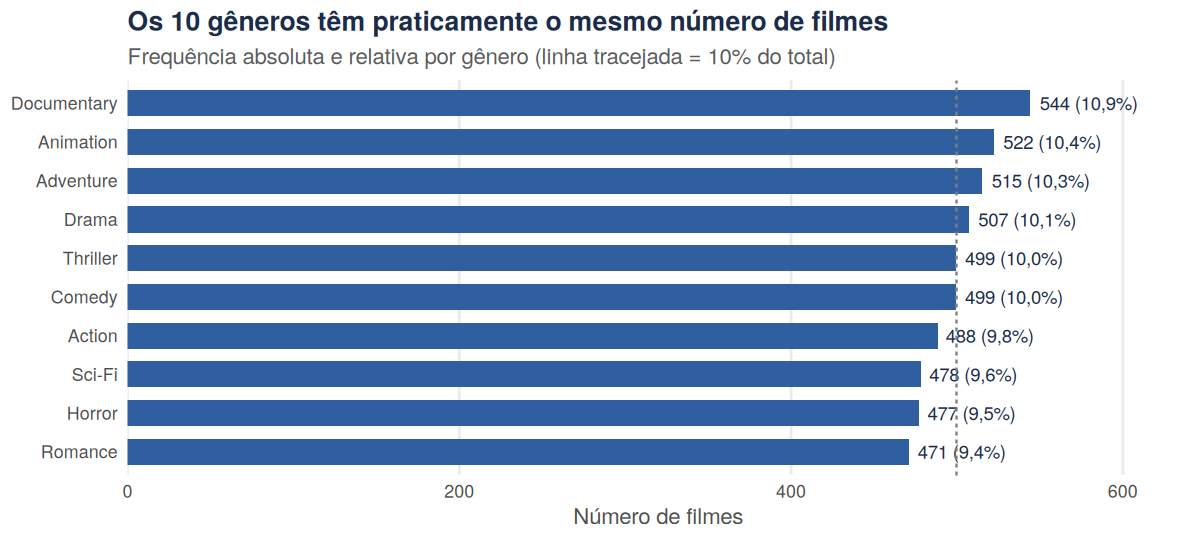

In [15]:
generos <- df %>%
  count(genre, sort = TRUE) %>%
  mutate(pct = 100 * n / sum(n))
generos

ggplot(generos, aes(x = n, y = reorder(genre, n))) +
  geom_col(fill = AZUL, width = 0.65) +
  geom_text(aes(label = paste0(br(n), " (", br(pct, 1), "%)")), hjust = -0.1, color = TINTA, size = 3.8) +
  geom_vline(xintercept = nrow(df) / 10, linetype = "dashed", color = "grey50") +
  scale_x_continuous(limits = c(0, 640), expand = c(0, 0)) +
  labs(title = "Os 10 gêneros têm praticamente o mesmo número de filmes",
       subtitle = "Frequência absoluta e relativa por gênero (linha tracejada = 10% do total)",
       x = "Número de filmes", y = NULL) +
  theme(panel.grid.major.y = element_blank(), panel.grid.major.x = element_line())

**Observações**

- Há **10 gêneros**, e cada um tem entre **471 (Romance, 9,4%)** e **544 filmes (Documentary, 10,9%)**: a distribuição é **praticamente uniforme**, em torno de 10% cada.
- Isso é bom para a modelagem: **nenhuma categoria é rara**, então a árvore tem amostras suficientes em cada gênero e não há necessidade de agrupar categorias em "Outros".
- Também significa que qualquer diferença na **taxa de blockbuster** entre os gêneros (analisada na seção 2.3) não vem de um gênero ter muito mais filmes que outro.

### 2.2.5 Década e ano: `decade` e `year`

decade,n,pct,anos_cobertos,filmes_por_ano
<fct>,<int>,<dbl>,<dbl>,<dbl>
1980s,1106,22.12,10,110.6
1990s,1081,21.62,10,108.1
2000s,1148,22.96,10,114.8
2010s,1079,21.58,10,107.9
2020s,586,11.72,5,117.2


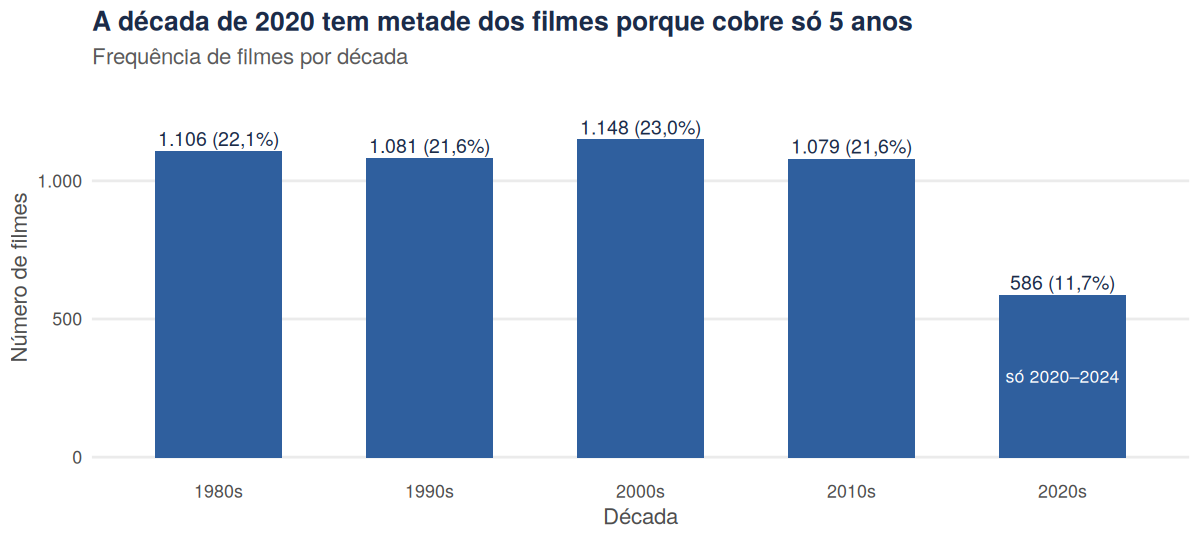

In [16]:
decadas <- df %>%
  count(decade) %>%
  mutate(pct = 100 * n / sum(n),
         anos_cobertos = c(10, 10, 10, 10, 5),
         filmes_por_ano = n / anos_cobertos)
decadas

ggplot(decadas, aes(x = decade, y = n)) +
  geom_col(fill = AZUL, width = 0.6) +
  geom_text(aes(label = paste0(br(n), " (", br(pct, 1), "%)")), vjust = -0.4, color = TINTA, size = 4) +
  annotate("text", x = 5, y = 586 / 2, label = "só 2020–2024", color = "white", size = 3.6) +
  scale_y_continuous(limits = c(0, 1300), labels = label_number(big.mark = ".", decimal.mark = ",")) +
  labs(title = "A década de 2020 tem metade dos filmes porque cobre só 5 anos",
       subtitle = "Frequência de filmes por década",
       x = "Década", y = "Número de filmes")

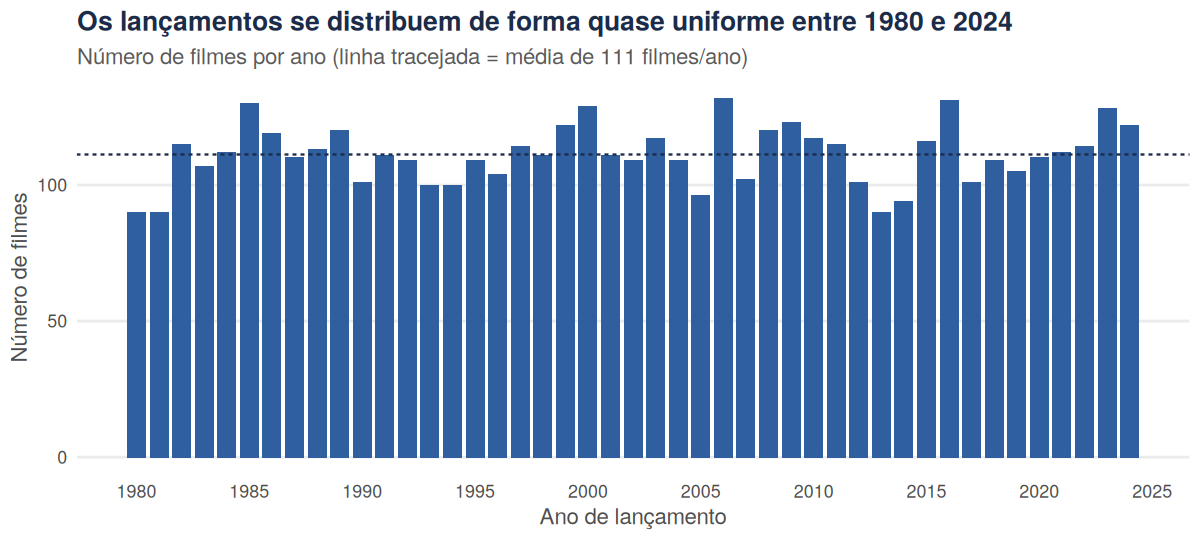

In [17]:
ggplot(df, aes(x = year)) +
  geom_bar(fill = AZUL, width = 0.8) +
  geom_hline(yintercept = mean(table(df$year)), linetype = "dashed", color = TINTA) +
  scale_x_continuous(breaks = seq(1980, 2025, 5)) +
  labs(title = "Os lançamentos se distribuem de forma quase uniforme entre 1980 e 2024",
       subtitle = sprintf("Número de filmes por ano (linha tracejada = média de %.0f filmes/ano)", mean(table(df$year))),
       x = "Ano de lançamento", y = "Número de filmes")

**Observações**

- As quatro décadas completas têm entre **1.079 e 1.148 filmes** (cerca de 22% cada). A década de **2020 tem só 586 (11,7%)**, mas isso não é falta de dados: ela cobre apenas **2020 a 2024**. Por ano, o ritmo é o mesmo das outras décadas (cerca de 110 filmes/ano).
- Por ano, a contagem varia entre **90 e 132 filmes**, em torno da média de **111**, sem tendência clara de crescimento: o dataset **não simula** o aumento real do número de lançamentos ao longo do tempo.
- Para o modelo, usaremos a **década** como variável categórica, como no plano do Projeto 1. `year` e `decade` carregam a mesma informação, então não faz sentido usar as duas.
- A década de 2020 tem menos filmes, mas ainda são 586, o suficiente para a árvore estimar a taxa de blockbuster nesse grupo.

### 2.2.6 Variáveis fora do modelo principal

Receita, nota, votos e popularidade **não** entram no modelo principal: a receita define o alvo (vazamento) e as outras três só são conhecidas depois da estreia. Ainda assim, elas aparecem nos experimentos de controle (seção 4), então vale conhecer suas distribuições.

In [18]:
fora <- c("revenue_usd", "rating", "vote_count", "popularity")
t(sapply(df[fora], function(x) round(unlist(resumo_num(x)), 2)))

,n,media,mediana,desvio,minimo,Q1,Q3,maximo,CV_pct,assimetria,outliers
revenue_usd,5000,131184400.53,23279983.0,501258050.25,14032.44,5707046.69,88871335.98,14955184373.97,382.10,14.62,640
rating,5000,6.00,6.0,1.49,1.00,5.00,7.00,10.00,24.92,-0.05,25
vote_count,5000,69321.52,21815.5,321030.62,87.00,7866.75,57666.75,18230861.00,463.10,40.33,548
popularity,5000,20.00,12.2,26.70,0.37,6.33,23.59,627.87,133.46,6.92,393


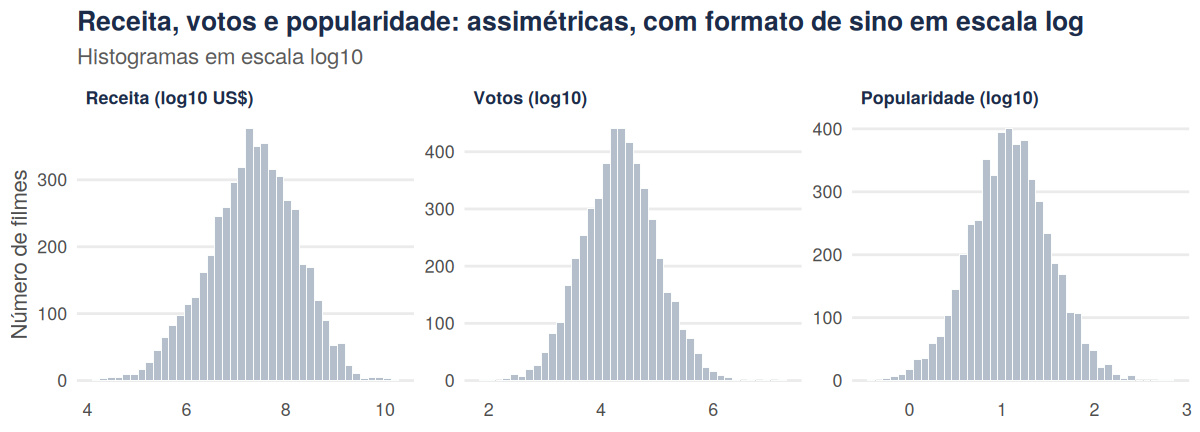

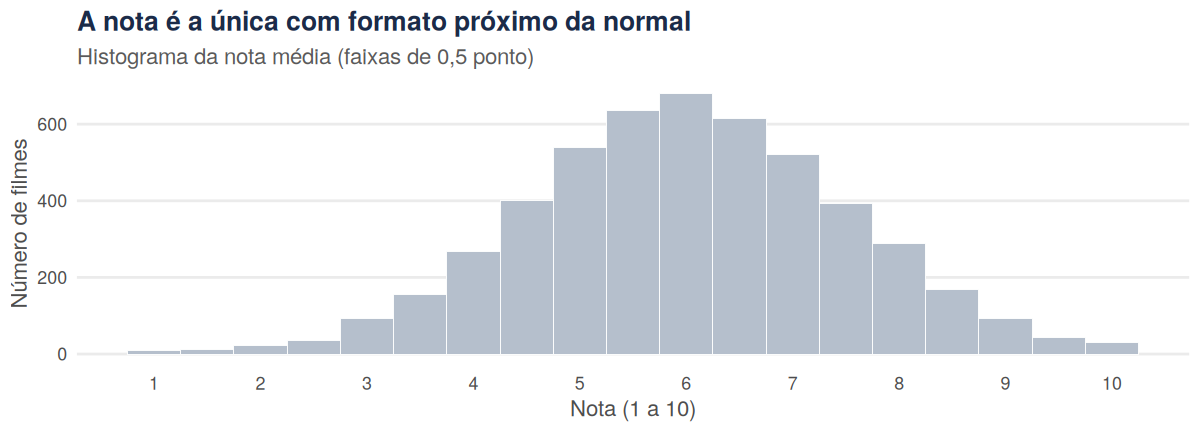

In [19]:
log_vars <- c("revenue_usd", "vote_count", "popularity")
options(repr.plot.height = 3.6)
df %>%
  select(all_of(log_vars)) %>%
  mutate(across(everything(), log10)) %>%
  pivot_longer(everything(), names_to = "variavel", values_to = "valor") %>%
  mutate(variavel = factor(variavel, levels = log_vars,
                           labels = c("Receita (log10 US$)", "Votos (log10)", "Popularidade (log10)"))) %>%
  ggplot(aes(x = valor)) +
  geom_histogram(bins = 40, fill = CINZA, color = "white", linewidth = 0.2) +
  facet_wrap(~ variavel, scales = "free", ncol = 3) +
  labs(title = "Receita, votos e popularidade: assimétricas, com formato de sino em escala log",
       subtitle = "Histogramas em escala log10",
       x = NULL, y = "Número de filmes") +
  theme(strip.text = element_text(face = "bold", color = TINTA, hjust = 0))

# A nota tem uma casa decimal: faixas de 0,5 ponto evitam "dentes" artificiais
ggplot(df, aes(x = rating)) +
  geom_histogram(binwidth = 0.5, boundary = 0.75, fill = CINZA, color = "white", linewidth = 0.2) +
  scale_x_continuous(breaks = 1:10) +
  labs(title = "A nota é a única com formato próximo da normal",
       subtitle = "Histograma da nota média (faixas de 0,5 ponto)",
       x = "Nota (1 a 10)", y = "Número de filmes")
options(repr.plot.height = 4.5)

**Observações**

- **Receita, votos e popularidade** seguem o mesmo padrão do orçamento: **assimetria à direita muito forte** (assimetria de 14,6, 40,3 e 6,9, respectivamente) e formato de sino em escala log. A receita mediana é de **US\$ 23,3 mi**, mas a média é **US\$ 131,2 mi**.
- A **nota** é a única com formato próximo da normal: média e mediana **6,0**, desvio padrão **1,5** e 95% dos filmes entre **3,1 e 8,9**. Há um pequeno acúmulo nas pontas (5 filmes com nota 1,0 e 20 com nota 10,0), outro sinal de valores cortados nos limites da escala pela simulação.
- Ficam fora do modelo principal pelos motivos definidos no Projeto 1: a receita vaza o alvo, e nota, votos e popularidade não existem no momento da decisão de investimento.

### Resumo da análise univariada

| Variável | Formato | Destaques | Implicação para o modelo |
|---|---|---|---|
| `blockbuster` | binária | **13,46%** sim × **86,54%** não | desbalanceada: usar F1/recall/AUROC e split estratificado |
| `budget_usd` | log-normal, assimetria 8,7 | mediana US\$ 15,0 mi, média US\$ 43,2 mi; 10,5% outliers | manter sem transformação: a árvore só usa a ordem dos valores |
| `runtime_min` | aproximadamente simétrica | média 109,4 min, DP 22,2; 2 outliers | sem tratamento |
| `genre` | quase uniforme | 10 gêneros com 9,4% a 10,9% cada | sem categorias raras; sem agrupar |
| `decade` | quase uniforme por ano | 2020s com metade dos filmes por cobrir só 5 anos | usar a década como categórica |

**Pontos que passam para a seção 2.3:** como a taxa de blockbuster varia entre gêneros, décadas e faixas de orçamento, e se o orçamento continua comparável entre décadas.

## 2.3 Análise Bivariada e Multivariada
<!-- Pessoa 3 -->

## 2.4 Insights da EDA
<!-- Pessoa 3 -->

# 3. Validação Estatística (Teste de Hipóteses)

## 3.1 Definição das Hipóteses
<!-- Pessoa 4 -->

## 3.2 Escolha e Execução do Teste
<!-- Pessoa 4 -->

## 3.3 Interpretação do p-valor
<!-- Pessoa 4 -->

# 4. Pré-processamento e Aplicação da Técnica

## 4.1 Preparação dos Dados para o Modelo
<!-- Pessoa 5 -->

## 4.2 Modelagem
<!-- Pessoa 5 -->

# 5. Resultados e Interpretação

## 5.1 Apresentação dos Resultados
<!-- Pessoa 6 -->

## 5.2 Análise Crítica dos Resultados
<!-- Pessoa 6 -->

# 6. Conclusão

## 6.1 Resumo dos Insights
<!-- Pessoa 6 -->

## 6.2 Recomendações Práticas
<!-- Pessoa 6 -->

## 6.3 Limitações e Próximos Passos
<!-- Pessoa 6 -->

# Referências

- AFONSO, A. M.; EBELL, M. H.; GONZALES, R.; STEIN, J.; GENTON, B.; SENN, N. The use of classification and regression trees to predict the likelihood of seasonal influenza. *Family Practice*, v. 29, p. 671–677, 2012. doi:10.1093/fampra/cms020.
- LEELAVATHI, V. R. *What Makes a Movie a Blockbuster? – 5,000 Films with Ratings, Budgets & Revenue*. Kaggle. Licença CC0.
- HASTIE, T.; TIBSHIRANI, R.; FRIEDMAN, J. *The Elements of Statistical Learning*. 2. ed. Springer, 2009.
- QUINLAN, J. R. Induction of Decision Trees. *Machine Learning*, v. 1, p. 81–106, 1986.
- THERNEAU, T.; ATKINSON, B. *rpart: Recursive Partitioning and Regression Trees*. Pacote R.
- WICKHAM, H. *ggplot2: Elegant Graphics for Data Analysis*. Springer, 2016.